# 03 · Framing, split & naive baselines

**Goal recap:** for each customer at a cutoff date, predict next-6-month `y_buy` and `y_spend`, using only history up to the cutoff.

**This notebook turns that sentence into data.** It decides four things:
1. **Exactly what the targets are**, including edge cases.
2. **The snapshot table:** one row per customer per cutoff.
3. **Which cutoffs are train / validation / test**, and why (label maturity).
4. **The bars to beat:** how good are dumb rules that need no model at all?

Step 4 matters more than it sounds. A model that can't clearly beat "next 6 months = last 6 months" isn't worth deploying, however fancy it is.

### 🧠 Predict first
1. At the validation cutoff (Dec 2010), which ranks future buyers better: **days since last purchase** or **spend in the last 6 months**?
2. On **MAE**, will the "last 6 months" baseline beat a model that simply predicts **£0 for everyone**?
3. Will "next 6 months = last 6 months" **over- or under-predict** total spend at the December cutoff? (Hint: what's in the "last 6 months" before December?)

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.clean import CLEAN_PARQUET
from src.split import (TRAIN_CUTOFFS, FINAL_CUTOFFS, VAL_CUTOFF, TEST_CUTOFF, DATA_START, DATA_END,
                       HORIZON_MONTHS, MARGIN, ONE_DAY, before_test, target_end,
                       build_snapshot, build_snapshots, time_folds, monthly_cutoffs)
from src.evaluate import classification_metrics, regression_metrics, decile_table, bootstrap_ci

pd.set_option("display.width", 160)
SEED = 42
np.random.seed(SEED)

purchases = before_test(pd.read_parquet(CLEAN_PARQUET))  # first guard: test window not even loaded

## 1. Target definitions (and the edge cases that hide inside them)

| Target | Definition | Type |
|---|---|---|
| `y_buy` | 1 if the customer has **any** purchase in the 6 months after the cutoff | classification |
| `y_spend` | total **gross** purchase value (£) in those 6 months; 0 if none | regression, zero-inflated |
| `y_ltv` | `y_spend × 30%` | regression (a rescaled `y_spend`) |

**Edge-case decisions** (each one is a choice; the alternative is in brackets):
- **A purchase on the cutoff day counts as history, not target.** The target window starts the next day. [Alternative: split by time of day. That's needlessly fiddly with daily snapshots.]
- **Spend is gross; returns are not netted.** A return in the target window of an order placed *before* the cutoff would make the target negative or understate it.
  Return behaviour is captured as a *feature* instead. [Alternative: net spend, closer to cash but noisier, and it mixes two time periods.]
- **30% margin is an assumption.** The data has revenue only. Because it's a constant multiplier, **every ranking metric is identical for `y_spend` and `y_ltv`**,
  so from here on we model `y_spend` and convert at the end. If margin varied by product, this would no longer be true.
- **No discounting:** over 6 months, the time value of money is negligible.
- **Who is scored:** customers with ≥ 1 purchase on or before the cutoff. Customers who first buy *after* the cutoff are a cold-start problem, out of scope.

## 2. Choosing cutoffs: working backwards from the end of the data

**The rule (label maturity):** a snapshot's label is only known 6 months after its cutoff. So each stage may only *train* on snapshots whose label had matured by then.

| Role | Cutoffs | Label windows end by | Why |
|---|---|---|---|
| **Test** | 2011-06-09 | 2011-12-09 (data end) | latest possible: the closest copy of "predict from today's data" |
| **Validation** | 2010-12-09 | 2011-06-09 (= test cutoff) | one horizon before test; its labels never touch the test window |
| **Train (selection)** | 2010-01-09 … 2010-06-09 | 2010-12-09 (= validation cutoff) | only labels known on the validation date |
| **Final refit** | 2010-01-09 … 2010-12-09 | 2011-06-09 (= test cutoff) | only labels known on the test date |

In [2]:
print("Train (selection):", [c.strftime("%Y-%m-%d") for c in TRAIN_CUTOFFS])
print("Validation:       ", VAL_CUTOFF.date())
print("Final refit:      ", f"{FINAL_CUTOFFS[0].date()} … {FINAL_CUTOFFS[-1].date()} ({len(FINAL_CUTOFFS)} cutoffs)")
print("Test:             ", TEST_CUTOFF.date())

# Second guard: the builder itself refuses to create labels inside the test window.
try:
    build_snapshot(purchases, TEST_CUTOFF)
except ValueError as e:
    print("\nGuard works →", e)

Train (selection): ['2010-01-09', '2010-02-09', '2010-03-09', '2010-04-09', '2010-05-09', '2010-06-09']
Validation:        2010-12-09
Final refit:       2010-01-09 … 2010-12-09 (12 cutoffs)
Test:              2011-06-09

Guard works → Target window for 2011-06-09 overlaps the test window; pass allow_test=True only in notebook 12.


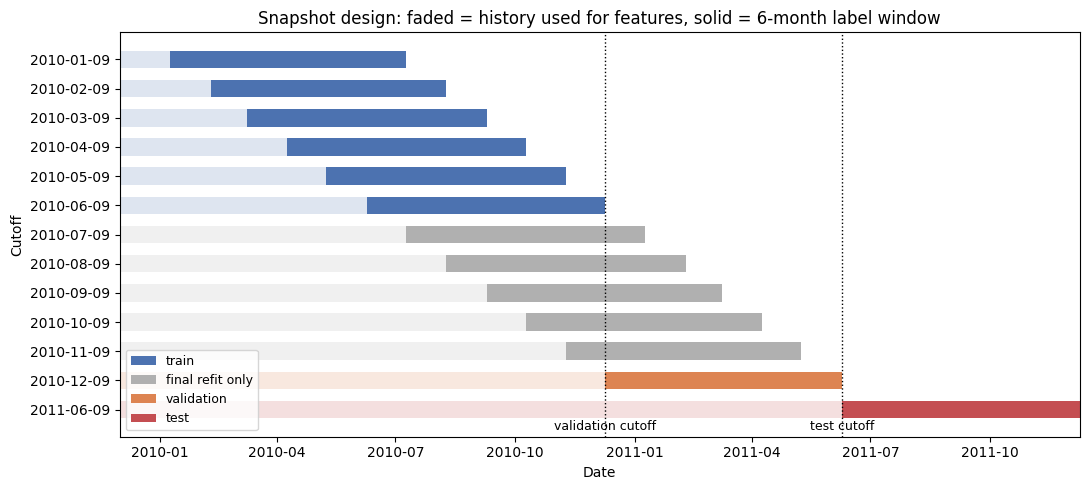

In [3]:
roles = ([(c, "train", "#4C72B0") for c in TRAIN_CUTOFFS]
         + [(c, "final refit only", "#B0B0B0") for c in FINAL_CUTOFFS if c not in TRAIN_CUTOFFS and c != VAL_CUTOFF]
         + [(VAL_CUTOFF, "validation", "#DD8452"), (TEST_CUTOFF, "test", "#C44E52")])

fig, ax = plt.subplots(figsize=(11, 5))
for y, (c, role, color) in enumerate(roles):
    ax.barh(y, (c - DATA_START).days, left=DATA_START, color=color, alpha=0.18, height=0.6)
    ax.barh(y, (target_end(c) - c).days, left=c, color=color, height=0.6,
            label=role if role not in ax.get_legend_handles_labels()[1] else None)
for x, name in [(VAL_CUTOFF, "validation cutoff"), (TEST_CUTOFF, "test cutoff")]:
    ax.axvline(x, color="black", ls=":", lw=1)
    ax.text(x, len(roles) - 0.3, name, ha="center", fontsize=9)
ax.set_yticks(range(len(roles)), [c.strftime("%Y-%m-%d") for c, _, _ in roles])
ax.invert_yaxis()
ax.set_xlim(DATA_START, DATA_END)
ax.set_title("Snapshot design: faded = history used for features, solid = 6-month label window")
ax.set_xlabel("Date")
ax.set_ylabel("Cutoff")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

**How to read it:** every solid blue bar (a training label) ends **before** the validation line, and the orange bar (the validation label) ends **exactly at** the test line.
Grey cutoffs (Jul–Nov) have labels running into the validation period. So they can't be training data for validation, but they **can** be:
- extra **validation folds** for tuning (each with its own expanding training set, section 5), and
- training data for the **final refit**, once all choices are frozen.

**Costs of this design** (to own in an interview):
- Only **6 training cutoffs**, all with spring/summer starts. Their label windows mostly overlap Q4 2010, while validation's doesn't (notebook 02).
- Early cutoffs have **short history** (Jan 2010 = 5 weeks of data). That's flagged as a feature in notebook 04.

## 3. Build the snapshot table

In [4]:
def role_of(c):
    if c in TRAIN_CUTOFFS:
        return "train"
    return "validation" if c == VAL_CUTOFF else "final refit only"


pool = build_snapshots(purchases, FINAL_CUTOFFS)
pool["role"] = pool["cutoff"].map(role_of)
print(f"{len(pool):,} snapshot rows from {pool['Customer ID'].nunique():,} customers")

by_cutoff = pool.groupby("cutoff").agg(role=("role", "first"), customers=("y_buy", "size"),
                                       buy_rate=("y_buy", "mean"), mean_spend=("y_spend", "mean"),
                                       median_spend_if_buy=("y_spend", lambda s: s[s > 0].median()))
by_cutoff.round(2)

33,254 snapshot rows from 4,282 customers


,role,customers,buy_rate,mean_spend,median_spend_if_buy
cutoff,,,,,
2010-01-09,train,1005,0.78,1981.54,935.55
2010-02-09,train,1453,0.75,1565.29,800.92
2010-03-09,train,1853,0.73,1427.74,750.08
2010-04-09,train,2212,0.71,1347.46,788.06
2010-05-09,train,2492,0.71,1332.92,805.81
2010-06-09,train,2772,0.71,1352.57,801.77
2010-07-09,final refit only,3010,0.69,1229.19,744.62
2010-08-09,final refit only,3178,0.67,1144.09,700.76
2010-09-09,final refit only,3348,0.64,1058.26,691.12


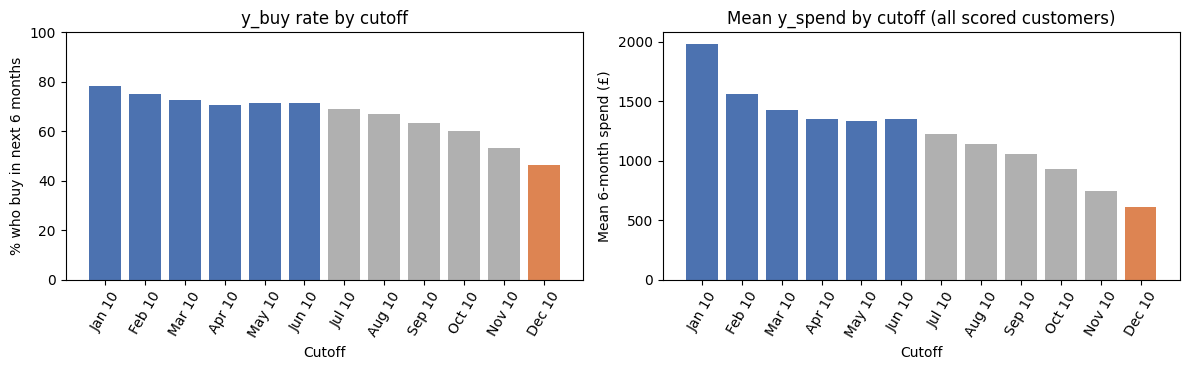

In [5]:
colors = by_cutoff["role"].map({"train": "#4C72B0", "final refit only": "#B0B0B0", "validation": "#DD8452"})
labels = by_cutoff.index.strftime("%b %y")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(labels, by_cutoff["buy_rate"] * 100, color=colors)
axes[0].set_title("y_buy rate by cutoff")
axes[0].set_xlabel("Cutoff")
axes[0].set_ylabel("% who buy in next 6 months")
axes[0].set_ylim(0, 100)

axes[1].bar(labels, by_cutoff["mean_spend"], color=colors)
axes[1].set_title("Mean y_spend by cutoff (all scored customers)")
axes[1].set_xlabel("Cutoff")
axes[1].set_ylabel("Mean 6-month spend (£)")
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

**Takeaway:** the targets **shift a lot over time**: the buy rate goes from about 72% across training cutoffs to 46% at validation, and mean spend from about £1,400 to about £615.
Blue = train, orange = validation, grey = final refit only.

**What this means:** a model's *ranking* can transfer across that shift, but its *level* (probabilities, total £) won't automatically.
A model trained on blue bars will **over-predict** at the orange one unless it has features that capture *why* the rate dropped (more dormant customers, an off-season window).
That's the first thing to check in notebooks 06–07: is the gap in calibration explained by features, or is it pure seasonality?

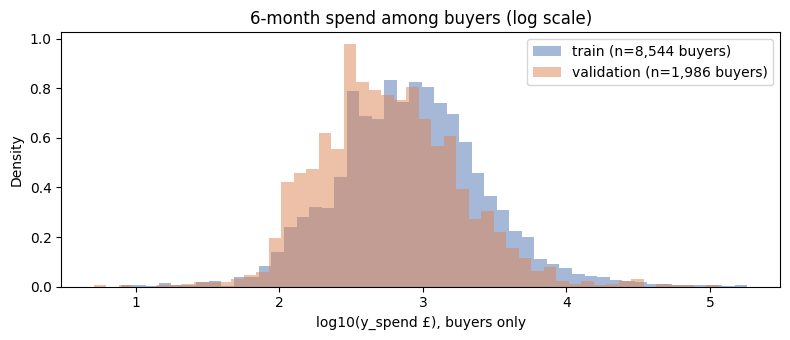

Train rows: 11,787 from 2,772 customers → mean 4.3 snapshots per customer


In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for role, color in [("train", "#4C72B0"), ("validation", "#DD8452")]:
    s = pool.loc[(pool["role"] == role) & (pool["y_spend"] > 0), "y_spend"]
    ax.hist(np.log10(s), bins=50, density=True, alpha=0.5, color=color, label=f"{role} (n={len(s):,} buyers)")
ax.set_title("6-month spend among buyers (log scale)")
ax.set_xlabel("log10(y_spend £), buyers only")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

per_cust = pool[pool["role"] == "train"].groupby("Customer ID").size()
print(f"Train rows: {per_cust.sum():,} from {len(per_cust):,} customers → mean {per_cust.mean():.1f} snapshots per customer")

**Takeaway:** among buyers, spend is roughly **log-normal**, and validation buyers spend somewhat less than training buyers (shifted left: no Q4 in the window).
The *shape* is stable, which is good news for a log-scale model.

**Correlated rows:** the average training customer appears in **about 4 of the 6** training snapshots. Those rows are near-duplicates: the same person, one month apart.
Consequences:
- The effective sample size is **closer to the number of customers than the number of rows**. Don't be impressed by "11k training rows".
- **Never split randomly by row.** The same customer would be in train and validation, and the model would partly recognise them rather than generalise.
- Bootstrap CIs on stacked data must resample **customers**, not rows. Validation is a single snapshot (one row per customer), so a row bootstrap is fine there.

## 4. Naive baselines: the bars to beat

The baselines use two quantities computed **only from history on or before the cutoff**. They involve no training at all, which is exactly the point.

In [7]:
def baseline_inputs(purchases: pd.DataFrame, cutoff: pd.Timestamp) -> pd.DataFrame:
    hist = purchases[purchases["InvoiceDate"] < cutoff + ONE_DAY]
    last = hist.groupby("Customer ID")["InvoiceDate"].max().dt.normalize()
    recent = hist[hist["InvoiceDate"] >= cutoff - pd.DateOffset(months=HORIZON_MONTHS) + ONE_DAY]
    return pd.DataFrame({
        "recency_days": (cutoff - last).dt.days,
        "spend_last_6m": recent.groupby("Customer ID")["Spend"].sum(),
    }).fillna({"spend_last_6m": 0.0})


def with_baselines(snap: pd.DataFrame, cutoff: pd.Timestamp) -> pd.DataFrame:
    return snap.merge(baseline_inputs(purchases, cutoff), left_on="Customer ID", right_index=True, how="left")


val = with_baselines(pool[pool["cutoff"] == VAL_CUTOFF], VAL_CUTOFF)
train = pool[pool["role"] == "train"]
print(f"Validation: {len(val):,} customers | buy rate {val['y_buy'].mean():.1%} | train buy rate {train['y_buy'].mean():.1%}")

Validation: 4,282 customers | buy rate 46.4% | train buy rate 72.5%


### 4a. Will they buy? (`y_buy`)

| Baseline | Idea | Gives a probability? |
|---|---|---|
| Constant = train buy rate | "everyone has the average chance" | yes (AUC = 0.5 by construction) |
| Rule: bought in last 90 days | the classic heuristic (yes/no) | no, just 0/1 |
| Score: recency | more recent → more likely | no, a ranking |
| Score: spend in last 6 months | more active → more likely | no, a ranking |

In [8]:
y = val["y_buy"]
p_const = np.full(len(val), train["y_buy"].mean())
p_oracle = np.full(len(val), y.mean())  # constant that already knows the validation rate (cheating, for reference)

clf = pd.DataFrame({
    "constant = train rate": classification_metrics(y, p_const),
    "constant = val rate (oracle)": classification_metrics(y, p_oracle),
    "rule: bought in last 90d": classification_metrics(y, (val["recency_days"] <= 90).astype(int), is_probability=False),
    "score: recency": classification_metrics(y, -val["recency_days"], is_probability=False),
    "score: spend last 6m": classification_metrics(y, val["spend_last_6m"], is_probability=False),
}).T
clf.round(3)

,roc_auc,pr_auc,log_loss,brier
constant = train rate,0.500,0.464,0.841,0.317
constant = val rate (oracle),0.500,0.464,0.691,0.249
rule: bought in last 90d,0.632,0.543,NaN,NaN
score: recency,0.699,0.649,NaN,NaN
score: spend last 6m,0.752,0.733,NaN,NaN


In [9]:
rule = val["recency_days"] <= 90
print(f"Rule 'bought in last 90d' flags {rule.mean():.0%} of customers")
print(f"  precision: {y[rule].mean():.0%} of flagged customers buy   |   recall: {rule[y == 1].mean():.0%} of buyers are flagged")
print(f"  …and {y[~rule].mean():.0%} of NOT-flagged customers buy anyway")

for name, score in [("recency", -val["recency_days"]), ("spend last 6m", val["spend_last_6m"])]:
    est, lo, hi = bootstrap_ci(lambda a, b: classification_metrics(a, b, False)["roc_auc"], y, score)
    print(f"AUC {name:<14} {est:.3f}  95% CI [{lo:.3f}, {hi:.3f}]")

Rule 'bought in last 90d' flags 67% of customers
  precision: 56% of flagged customers buy   |   recall: 81% of buyers are flagged
  …and 26% of NOT-flagged customers buy anyway


AUC recency        0.699  95% CI [0.683, 0.715]


AUC spend last 6m  0.752  95% CI [0.737, 0.768]


**Takeaways:**
- **Spend in the last 6 months ranks buyers better than recency** (AUC about 0.75 vs. 0.70, with non-overlapping CIs). "How engaged" beats "how recent" here, because it folds in frequency *and* recency.
- The famous **"bought in last 90 days" rule is weak** (AUC about 0.63): it throws away everything except one yes/no bit, flags two-thirds of customers, and about a quarter of the *non*-flagged customers buy anyway.
- **Calibration:** the constant "train rate" (about 72%) has much worse log loss than the oracle constant (46%). That gap is **pure base-rate shift**, with no ranking involved.
  Any model trained on spring/summer cutoffs inherits this problem at the December cutoff.

**Bars to beat for `y_buy`:** AUC > 0.75 (and outside its CI); log loss well below the train-rate constant.

### 4b. How much will they spend? (`y_spend`)

In [10]:
ys = val["y_spend"]
preds = {
    "predict £0": np.zeros(len(val)),
    "predict train mean": np.full(len(val), train["y_spend"].mean()),
    "next 6m = last 6m": val["spend_last_6m"].values,
}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    reg = pd.DataFrame({k: regression_metrics(ys, v) for k, v in preds.items()}).T
reg.loc[["predict £0", "predict train mean"], ["spearman", "gini", "top10_capture", "top10_lift"]] = np.nan  # no ranking in a constant
reg.round(3)

,mae,rmse,spearman,gini,top10_capture,top10_lift,total_pct_error
predict £0,614.669,3044.939,NaN,NaN,NaN,NaN,-1.000
predict train mean,1409.592,3094.117,NaN,NaN,NaN,NaN,1.341
next 6m = last 6m,717.171,2734.279,0.537,0.829,0.615,6.155,0.836


**Takeaways (two surprises):**
1. **Predicting £0 for everyone beats "last 6 months" on MAE.** More than half the validation customers spend £0, so the median is £0, and MAE rewards predicting the median.
   **MAE is a poor headline metric for a zero-inflated target:** it prefers a useless model that never says anyone will buy. We report it, but we never *select* on it alone.
2. **"Last 6 months" over-predicts total spend by about 84%.** The last 6 months before Dec 2010 contain the Q4 peak, and the next 6 months don't.
   The baseline **copies seasonality into the wrong season**. That's notebook 02's finding, now with a price tag.

Its **ranking** is still decent (Spearman about 0.54, Gini about 0.83): it puts the right customers near the top even though it gets the level wrong.

In [11]:
dec = decile_table(ys, val["spend_last_6m"])
print(dec.round(2).to_string())

for name, fn in [("Spearman", lambda a, b: regression_metrics(a, b)["spearman"]),
                 ("Top-10% capture", lambda a, b: regression_metrics(a, b)["top10_capture"])]:
    est, lo, hi = bootstrap_ci(fn, ys, val["spend_last_6m"], n_boot=300)
    print(f"{name:<16} {est:.3f}  95% CI [{lo:.3f}, {hi:.3f}]")

        customers  mean_pred  mean_actual  total_actual  share_of_actual  lift
decile                                                                        
1             429    6690.00      3777.14    1620392.46             0.62  6.14
2             428    1625.35       786.72     336714.44             0.13  1.28
3             428    1032.31       498.49     213354.11             0.08  0.81
4             428     700.99       322.45     138009.96             0.05  0.52
5             428     498.95       197.08      84350.51             0.03  0.32
6             428     347.35       171.98      73609.14             0.03  0.28
7             428     242.45       120.20      51446.53             0.02  0.20
8             428     129.65        70.25      30065.78             0.01  0.11
9             428       5.64       100.08      42836.38             0.02  0.16
10            429       0.00        96.12      41233.48             0.02  0.16


Spearman         0.537  95% CI [0.510, 0.562]


Top-10% capture  0.615  95% CI [0.558, 0.664]


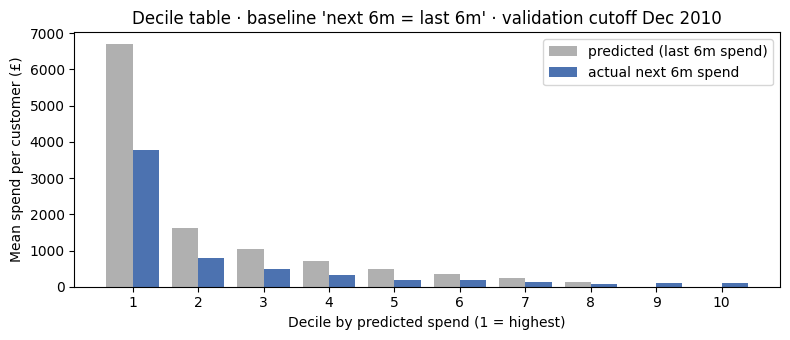

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(1, 11)
ax.bar(x - 0.2, dec["mean_pred"], width=0.4, label="predicted (last 6m spend)", color="#B0B0B0")
ax.bar(x + 0.2, dec["mean_actual"], width=0.4, label="actual next 6m spend", color="#4C72B0")
ax.set_xticks(x)
ax.set_title("Decile table · baseline 'next 6m = last 6m' · validation cutoff Dec 2010")
ax.set_xlabel("Decile by predicted spend (1 = highest)")
ax.set_ylabel("Mean spend per customer (£)")
ax.legend()
plt.tight_layout()
plt.show()

**Takeaway:** the ordering is right through decile 8, and the **top 10% by last-6m spend capture about 62% of next-6m revenue**.
But in deciles 1–8 the **predicted bars are about 2× the actual ones**: the level is off because of the seasonal mismatch.
**Deciles 9–10 are the baseline's blind spot:** these customers spent £0 in the last 6 months, so it predicts £0, yet they spend about £100 on average, *more* than decile 8.
Those are dormant customers coming back, and a rule that only looks at the last 6 months can't see them. A model using longer history (lifetime spend, typical gap) should.

**Bars to beat for `y_spend`:** Spearman > 0.54, top-10% capture > about 62%, Gini > 0.83, **and** a total % error much closer to 0.

## 5. Are the baselines stable across time? (more than one validation fold)
One validation cutoff is one draw. The grey cutoffs (Sep–Nov 2010) can act as extra validation folds, each scored on its own expanding training set.
That's exactly the time-series CV we'll use for tuning in notebook 08.

In [13]:
folds = time_folds(monthly_cutoffs("2010-09", "2010-12"))
for train_cuts, v in folds:
    print(f"validate {v.date()}  ←  train on {train_cuts[0].strftime('%b')}–{train_cuts[-1].strftime('%b %Y')} ({len(train_cuts)} cutoffs)")

rows = []
for _, v in folds:
    s = with_baselines(pool[pool["cutoff"] == v], v)
    rows.append({"cutoff": v.strftime("%b %Y"), "buy_rate": s["y_buy"].mean(),
                 "AUC recency": classification_metrics(s["y_buy"], -s["recency_days"], False)["roc_auc"],
                 "AUC spend6m": classification_metrics(s["y_buy"], s["spend_last_6m"], False)["roc_auc"],
                 **{k: regression_metrics(s["y_spend"], s["spend_last_6m"])[k] for k in ["spearman", "top10_capture", "total_pct_error"]}})
stab = pd.DataFrame(rows).set_index("cutoff")
stab.round(3)

validate 2010-09-09  ←  train on Jan–Mar 2010 (3 cutoffs)
validate 2010-10-09  ←  train on Jan–Apr 2010 (4 cutoffs)
validate 2010-11-09  ←  train on Jan–May 2010 (5 cutoffs)
validate 2010-12-09  ←  train on Jan–Jun 2010 (6 cutoffs)


,buy_rate,AUC recency,AUC spend6m,spearman,top10_capture,total_pct_error
cutoff,,,,,,
Sep 2010,0.635,0.656,0.707,0.528,0.548,0.017
Oct 2010,0.602,0.658,0.710,0.519,0.564,0.150
Nov 2010,0.534,0.673,0.724,0.523,0.580,0.463
Dec 2010,0.464,0.699,0.752,0.537,0.615,0.836


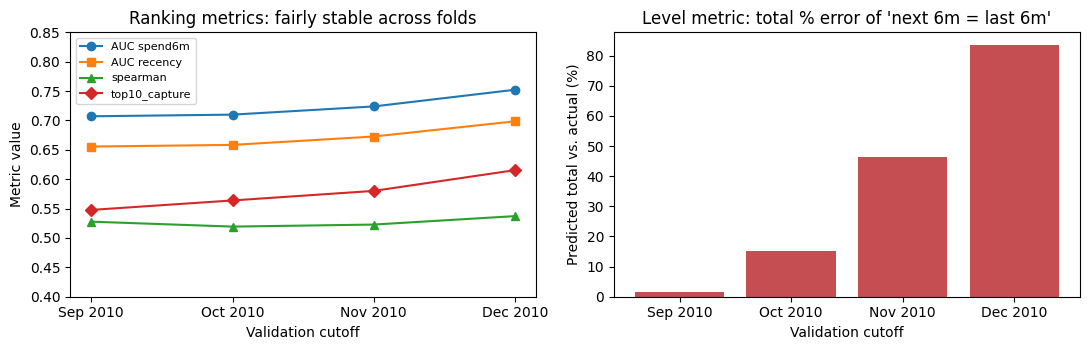

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for col, m in [("AUC spend6m", "o"), ("AUC recency", "s"), ("spearman", "^"), ("top10_capture", "D")]:
    axes[0].plot(stab.index, stab[col], marker=m, label=col)
axes[0].set_ylim(0.4, 0.85)
axes[0].set_title("Ranking metrics: fairly stable across folds")
axes[0].set_xlabel("Validation cutoff")
axes[0].set_ylabel("Metric value")
axes[0].legend(fontsize=8)

axes[1].bar(stab.index, stab["total_pct_error"] * 100, color="#C44E52")
axes[1].set_title("Level metric: total % error of 'next 6m = last 6m'")
axes[1].set_xlabel("Validation cutoff")
axes[1].set_ylabel("Predicted total vs. actual (%)")
plt.tight_layout()
plt.show()

**Takeaway:** the **ranking** metrics move only a little from September to December (AUC 0.71 → 0.75, Spearman 0.52–0.54), while the **total-spend error** explodes from about +2% to about +84%
as the "last 6 months" fill up with Q4 and the next 6 months empty out.

**This is the strongest argument in the project for selecting models on ranking metrics:** ranking is a property of the customers; level is a property of the season.
For model comparison we'll use **several folds**, not just December, so a model that only wins in one season doesn't fool us.

## 6. Summary

| Decision | Choice | Alternative not picked |
|---|---|---|
| Target | gross 6-month spend; `y_buy = y_spend > 0`; LTV = 30% × spend | net spend (mixes periods, can go negative) |
| Cutoffs | label maturity: train Jan–Jun 2010, validation Dec 2010, test Jun 2011 | random split (uses the future); later train cutoffs (labels overlap validation) |
| Tuning folds | expanding window, validate Sep–Dec 2010 | k-fold by row (same customer on both sides) |
| Lead metrics | AUC; Spearman, top-10% capture, Gini | MAE (prefers "predict £0") |
| Level metrics | log loss, Brier, total % error: reported, interpreted with seasonality in mind | ignoring them (budgets need levels) |

**Bars to beat at validation (Dec 2010):**

| Task | Best baseline | Score |
|---|---|---|
| `y_buy` ranking | spend in last 6 months | AUC ≈ 0.75 |
| `y_spend` ranking | next 6m = last 6m | Spearman ≈ 0.54, top-10% capture ≈ 62%, Gini ≈ 0.83 |
| `y_spend` level | next 6m = last 6m | total error ≈ +84% (easy to beat, if features capture seasonality) |

In [15]:
out = pool.drop(columns="role")
out.to_parquet(Path(CLEAN_PARQUET).parent / "snapshot_targets.parquet", index=False)
print(f"Saved {len(out):,} snapshot rows (cutoffs {out['cutoff'].min().date()} … {out['cutoff'].max().date()})")

Saved 33,254 snapshot rows (cutoffs 2010-01-09 … 2010-12-09)


### 🧠 Interpret
1. Check your predictions: recency vs. 6-month spend, £0 vs. last-6m on MAE, over- vs. under-prediction. Which one would you have got wrong in an interview?
2. A stakeholder says: *"Our new model has a lower MAE than the old one, so let's ship it."* What two questions do you ask before agreeing?
3. Why does the total % error of the "last 6 months" baseline grow from September to December, while its AUC stays flat? Explain it to a non-technical PM in two sentences.
4. We have about 11k training rows but only about 2.8k distinct customers. Which number is closer to our real sample size, and how should that change how complex a model we try?
5. **ARQ:** what's the "last 6 months" baseline for FX volume, and what seasonal effect (e.g. December remittances, summer travel) could make it mislead the same way?